In [1]:
# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset
data = pd.read_csv('online_shoppers_intention.csv')
print("Dataset loaded successfully!")

Dataset loaded successfully!


In [2]:
# Check dataset shape
print("Shape:", data.shape)

# Check the data 
print(data.info())

# Check missing values
print(data.isnull().sum().sum())

Shape: (12330, 18)
<class 'pandas.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  str    
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   12330 non-null  int64  
 14  TrafficType   

In [3]:
# Separate features and target
X = data.drop('Revenue', axis=1)
Y = data['Revenue']

print("Features shape:", X.shape)
print("Target shape:", Y.shape)

Features shape: (12330, 17)
Target shape: (12330,)


In [4]:
# Check target variable distribution
print(Y.value_counts())

# Percentage distribution
print(Y.value_counts(normalize=True) * 100)

Revenue
False    10422
True      1908
Name: count, dtype: int64
Revenue
False    84.525547
True     15.474453
Name: proportion, dtype: float64


We could see that the data is imbalanced with 85% people's intention is not purchasing and 15% purchasing.

In [5]:
# Split training and testing data
from sklearn.model_selection import train_test_split

# Since data is imbalanced using stratified distribution
X_train, X_test, Y_train, Y_test = train_test_split(X, Y,test_size=0.2,random_state=42,stratify=Y)

# Print traning and testing data shape
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (9864, 17)
Testing data: (2466, 17)


Encoding categorical features since our models require numerical inputs.

In [6]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Identifying numerical, categorical and Boolean columns
numerical = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical = ['Month', 'VisitorType']
boolean = ['Weekend']

preprocessor = ColumnTransformer(transformers=[('num', StandardScaler(), numerical),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical),('bool', 'passthrough', boolean)])

# Logistic Regression

In [7]:
# To create a pipeline combining preprocessing and Logistic Regression
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

 # Train Logistic Regression with balanced class weights
log_reg = Pipeline([('preprocessor', preprocessor),  # Preprocessor features are encoded as necessary
                    ('classifier', LogisticRegression(max_iter=1000, class_weight='balanced'))]) # Train logistic regression

In [8]:
# Train the pipeline on the training data
log_reg.fit(X_train, Y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[bool](2,)","[False, True]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](17,)","['Administrative','Administrative_Duration','Informational',..., 'TrafficType','VisitorType','Weekend']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,17
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``

In [9]:
# Predict class labels and purchase probabilities
Y_pred_lr = log_reg.predict(X_test)
Y_prob_lr = log_reg.predict_proba(X_test)[:, 1]

In [10]:
# Import evaluation metrics
from sklearn.metrics import (
    accuracy_score, roc_auc_score, precision_score,
    recall_score, f1_score, matthews_corrcoef
)

# Calculate evaluation metrics
log_reg_metrics = {
    'Accuracy': accuracy_score(Y_test, Y_pred_lr),
    'AUC': roc_auc_score(Y_test, Y_prob_lr),
    'Precision': precision_score(Y_test, Y_pred_lr, zero_division=0),
    'Recall': recall_score(Y_test, Y_pred_lr, zero_division=0),
    'F1': f1_score(Y_test, Y_pred_lr, zero_division=0),
    'MCC': matthews_corrcoef(Y_test, Y_pred_lr)
}

# Display the results
print("Logistic Regression Performance:")
for metric, score in log_reg_metrics.items():
    print(f"{metric}: {score:.4f}")

Logistic Regression Performance:
Accuracy: 0.8500
AUC: 0.8962
Precision: 0.5107
Recall: 0.7487
F1: 0.6072
MCC: 0.5330


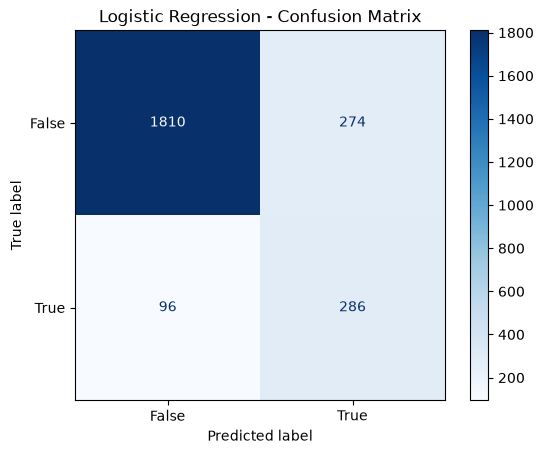

In [11]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Generate and display the confusion matrix
log_reg_cm = confusion_matrix(Y_test, Y_pred_lr)

ConfusionMatrixDisplay(
    confusion_matrix=log_reg_cm,
    display_labels=log_reg.classes_).plot(cmap='Blues')

plt.title('Logistic Regression - Confusion Matrix')
plt.show()

In [12]:
# Generate the classification report
from sklearn.metrics import classification_report

print("Logistic Regression - Classification Report")
print(classification_report(Y_test, Y_pred_lr, zero_division=0))

Logistic Regression - Classification Report
              precision    recall  f1-score   support

       False       0.95      0.87      0.91      2084
        True       0.51      0.75      0.61       382

    accuracy                           0.85      2466
   macro avg       0.73      0.81      0.76      2466
weighted avg       0.88      0.85      0.86      2466



# Decision Tree Classifier

In [13]:
# Import Decision Tree classifier
from sklearn.tree import DecisionTreeClassifier

# Pipeline combining preprocessing and Decision Tree
dec_tree = Pipeline([('preprocessor', preprocessor),
                     ('classifier', DecisionTreeClassifier(random_state=42, class_weight='balanced'))])

In [14]:
# Training Decision Tree pipeline on the training data
dec_tree.fit(X_train, Y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[bool](2,)","[False, True]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](17,)","['Administrative','Administrative_Duration','Informational',..., 'TrafficType','VisitorType','Weekend']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,17
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``

In [15]:
# Predict class labels and purchase probabilities
Y_pred_dt = dec_tree.predict(X_test)
Y_prob_dt = dec_tree.predict_proba(X_test)[:, 1]

In [16]:
# Evaluation metrics
dt_metrics = {
    'Accuracy': accuracy_score(Y_test, Y_pred_dt),
    'AUC': roc_auc_score(Y_test, Y_prob_dt),
    'Precision': precision_score(Y_test, Y_pred_dt, zero_division=0),
    'Recall': recall_score(Y_test, Y_pred_dt, zero_division=0),
    'F1': f1_score(Y_test, Y_pred_dt, zero_division=0),
    'MCC': matthews_corrcoef(Y_test, Y_pred_dt)}

# Display the results
print("Decision Tree Performance:")
for metric, score in dt_metrics.items():
    print(f"{metric}: {score:.4f}")

Decision Tree Performance:
Accuracy: 0.8544
AUC: 0.7033
Precision: 0.5331
Recall: 0.4843
F1: 0.5075
MCC: 0.4230


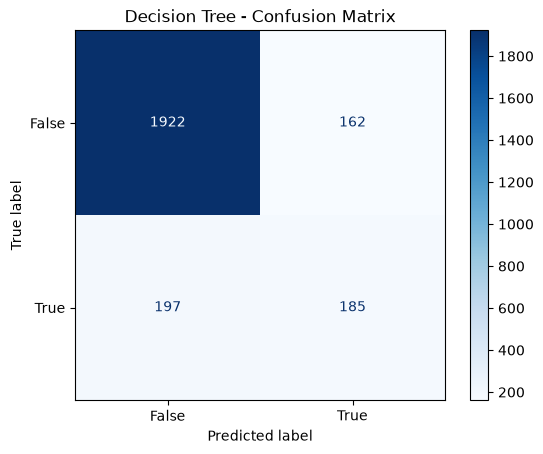

In [17]:
# Generate and display the Decision Tree confusion matrix
dec_tree_cm = confusion_matrix(Y_test, Y_pred_dt)

ConfusionMatrixDisplay(confusion_matrix=dec_tree_cm,
    display_labels=dec_tree.classes_).plot(cmap='Blues')

plt.title('Decision Tree - Confusion Matrix')
plt.show()

In [18]:
print("Decision Classifier - Classification Report")
print(classification_report(Y_test, Y_pred_dt, zero_division=0))

Decision Classifier - Classification Report
              precision    recall  f1-score   support

       False       0.91      0.92      0.91      2084
        True       0.53      0.48      0.51       382

    accuracy                           0.85      2466
   macro avg       0.72      0.70      0.71      2466
weighted avg       0.85      0.85      0.85      2466



# K-Nearest Neighbor Classifier

In [19]:
# Import K-Nearest Neighbors classifier
from sklearn.neighbors import KNeighborsClassifier

# Create a pipeline combining preprocessing and KNN
knn = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', KNeighborsClassifier(n_neighbors=5))])

In [20]:
# Train the KNN pipeline on the training data
knn.fit(X_train, Y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[bool](2,)","[False, True]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](17,)","['Administrative','Administrative_Duration','Informational',..., 'TrafficType','VisitorType','Weekend']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,17
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``

In [21]:
# Predict class labels and purchase probabilities
Y_pred_knn = knn.predict(X_test)
Y_prob_knn = knn.predict_proba(X_test)[:, 1]

In [22]:
knn_metrics = {
    'Accuracy': accuracy_score(Y_test, Y_pred_knn),
    'AUC': roc_auc_score(Y_test, Y_prob_knn),
    'Precision': precision_score(Y_test, Y_pred_knn, zero_division=0),
    'Recall': recall_score(Y_test, Y_pred_knn, zero_division=0),
    'F1': f1_score(Y_test, Y_pred_knn, zero_division=0),
    'MCC': matthews_corrcoef(Y_test, Y_pred_knn)
}

knn_metrics

{'Accuracy': 0.8718572587185726,
 'AUC': 0.7784924530956375,
 'Precision': 0.6434782608695652,
 'Recall': 0.387434554973822,
 'F1': 0.48366013071895425,
 'MCC': 0.43308057776316294}

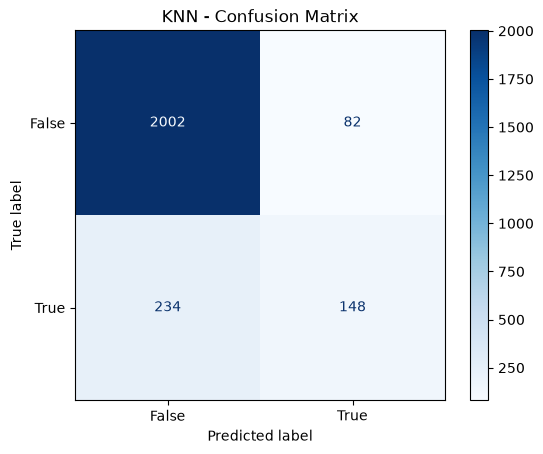

In [23]:
# Generate and display the KNN confusion matrix
knn_cm = confusion_matrix(Y_test, Y_pred_knn)

ConfusionMatrixDisplay(confusion_matrix=knn_cm,
    display_labels=knn.classes_).plot(cmap='Blues')

plt.title('KNN - Confusion Matrix')
plt.show()

In [24]:
print("K-Nearest Neighbors - Classification Report")
print(classification_report(Y_test, Y_pred_knn, zero_division=0))

K-Nearest Neighbors - Classification Report
              precision    recall  f1-score   support

       False       0.90      0.96      0.93      2084
        True       0.64      0.39      0.48       382

    accuracy                           0.87      2466
   macro avg       0.77      0.67      0.71      2466
weighted avg       0.86      0.87      0.86      2466



# Naive Bayes Classifier - Gaussian 

In [25]:
# Since Gaussian Naive Bayes requires expects dense input, this requires different preprocessing.
dense_preprocessor = ColumnTransformer(transformers=[
    ('num', StandardScaler(), numerical),
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical),
    ('bool', 'passthrough', boolean)], sparse_threshold=0)

In [26]:
# Import Gaussian Naive Bayes classifier
from sklearn.naive_bayes import GaussianNB

# Create a pipeline combining preprocessing and Gaussian Naive Bayes
guass_nb = Pipeline([
    ('preprocessor', dense_preprocessor),
    ('classifier', GaussianNB())])

In [27]:
# Train the Gaussian Naive Bayes pipeline on the training data
guass_nb.fit(X_train, Y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[bool](2,)","[False, True]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](17,)","['Administrative','Administrative_Duration','Informational',..., 'TrafficType','VisitorType','Weekend']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,17
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...), ...]"
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0``

In [28]:
# Predict class labels and purchase probabilities
Y_pred_nb = guass_nb.predict(X_test)
Y_prob_nb = guass_nb.predict_proba(X_test)[:, 1]

In [29]:
guass_nb_metrics = {
    'Accuracy': accuracy_score(Y_test, Y_pred_nb),
    'AUC': roc_auc_score(Y_test, Y_prob_nb),
    'Precision': precision_score(Y_test, Y_pred_nb, zero_division=0),
    'Recall': recall_score(Y_test, Y_pred_nb, zero_division=0),
    'F1': f1_score(Y_test, Y_pred_nb, zero_division=0),
    'MCC': matthews_corrcoef(Y_test, Y_pred_nb)}

guass_nb_metrics

{'Accuracy': 0.6735604217356043,
 'AUC': 0.7939009255258213,
 'Precision': 0.2940603700097371,
 'Recall': 0.7905759162303665,
 'F1': 0.42867281760113557,
 'MCC': 0.32490913703743013}

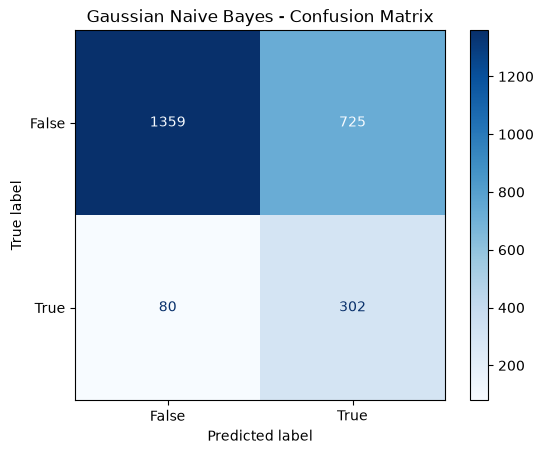

In [30]:
# Generate and display the Gaussian Naive Bayes confusion matrix
guass_nb_cm = confusion_matrix(Y_test, Y_pred_nb)

ConfusionMatrixDisplay(
    confusion_matrix=guass_nb_cm,
    display_labels=guass_nb.classes_
).plot(cmap='Blues')

plt.title('Gaussian Naive Bayes - Confusion Matrix')
plt.show()

In [31]:
print("Gaussian Naive Bayes - Classification Report")
print(classification_report(Y_test, Y_pred_nb, zero_division=0))

Gaussian Naive Bayes - Classification Report
              precision    recall  f1-score   support

       False       0.94      0.65      0.77      2084
        True       0.29      0.79      0.43       382

    accuracy                           0.67      2466
   macro avg       0.62      0.72      0.60      2466
weighted avg       0.84      0.67      0.72      2466



# Support Vector Machine

In [32]:
from sklearn.svm import SVC
from sklearn.calibration import CalibratedClassifierCV

# Create a pipeline combining preprocessing and calibrated SVM
svm = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', CalibratedClassifierCV(SVC(kernel='rbf', class_weight='balanced', random_state=42), ensemble=False))])

In [33]:
# Train the SVM pipeline on the training data
svm.fit(X_train, Y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[bool](2,)","[False, True]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](17,)","['Administrative','Administrative_Duration','Informational',..., 'TrafficType','VisitorType','Weekend']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,17
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``

In [34]:
# Predict class labels and purchase probabilities
Y_pred_svm = svm.predict(X_test)
Y_prob_svm = svm.predict_proba(X_test)[:, 1]

In [35]:
svm_metrics = {
    'Accuracy': accuracy_score(Y_test, Y_pred_svm),
    'AUC': roc_auc_score(Y_test, Y_prob_svm),
    'Precision': precision_score(Y_test, Y_pred_svm, zero_division=0),
    'Recall': recall_score(Y_test, Y_pred_svm, zero_division=0),
    'F1': f1_score(Y_test, Y_pred_svm, zero_division=0),
    'MCC': matthews_corrcoef(Y_test, Y_pred_svm)
}

svm_metrics

{'Accuracy': 0.8832116788321168,
 'AUC': 0.8860728964637077,
 'Precision': 0.6690647482014388,
 'Recall': 0.4869109947643979,
 'F1': 0.5636363636363636,
 'MCC': 0.5065331631466592}

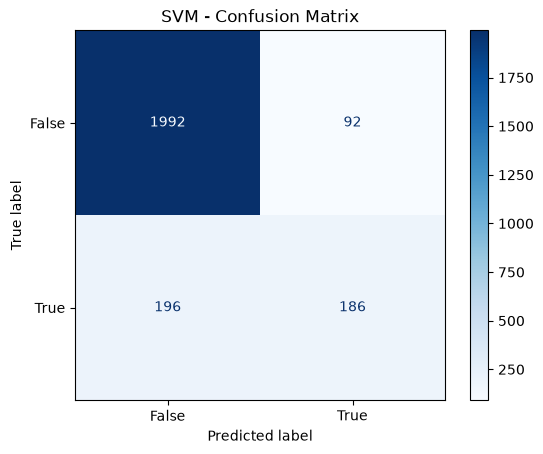

In [36]:
# Generate and display the SVM confusion matrix
svm_cm = confusion_matrix(Y_test, Y_pred_svm)

ConfusionMatrixDisplay(
    confusion_matrix=svm_cm,
    display_labels=svm.classes_
).plot(cmap='Blues')

plt.title('SVM - Confusion Matrix')
plt.show()

In [37]:
print("Support Vector Machine - Classification Report")
print(classification_report(Y_test, Y_pred_svm, zero_division=0))

Support Vector Machine - Classification Report
              precision    recall  f1-score   support

       False       0.91      0.96      0.93      2084
        True       0.67      0.49      0.56       382

    accuracy                           0.88      2466
   macro avg       0.79      0.72      0.75      2466
weighted avg       0.87      0.88      0.88      2466



In [38]:
# Evaluation metrics of all five classifiers
import pandas as pd

model_results = {
    'Logistic Regression': log_reg_metrics,
    'Decision Tree': dt_metrics,
    'KNN': knn_metrics,
    'Gaussian Naive Bayes': guass_nb_metrics,
    'SVM': svm_metrics
}

comparison_df = pd.DataFrame(model_results).T

comparison_df

,Accuracy,AUC,Precision,Recall,F1,MCC
Logistic Regression,0.849959,0.896225,0.510714,0.748691,0.607219,0.533041
Decision Tree,0.854420,0.703279,0.533141,0.484293,0.507545,0.423032
KNN,0.871857,0.778492,0.643478,0.387435,0.483660,0.433081
Gaussian Naive Bayes,0.673560,0.793901,0.294060,0.790576,0.428673,0.324909
SVM,0.883212,0.886073,0.669065,0.486911,0.563636,0.506533


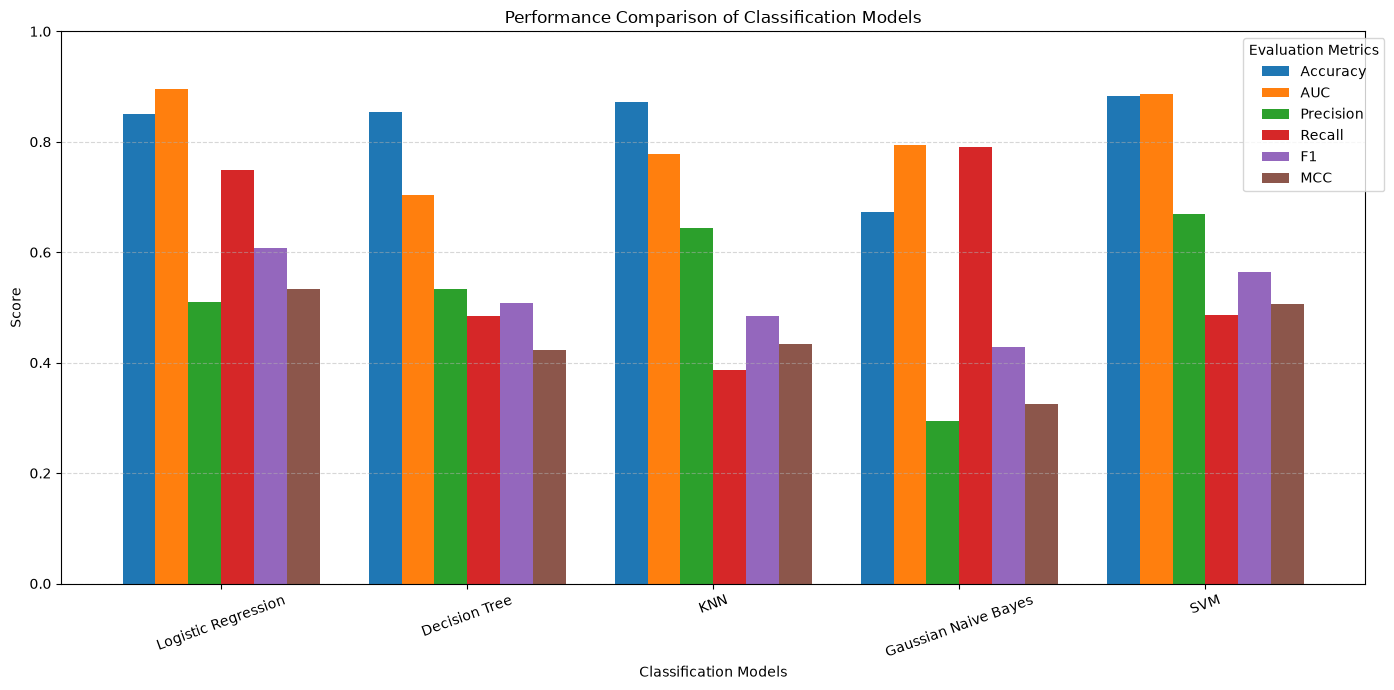

In [39]:
# Plot comparison of evaluation metrics
comparison_df.plot(
    kind='bar',
    figsize=(14, 7),
    width=0.8
)

plt.title('Performance Comparison of Classification Models')
plt.xlabel('Classification Models')
plt.ylabel('Score')
plt.xticks(rotation=20)
plt.ylim(0, 1)
plt.legend(title='Evaluation Metrics', bbox_to_anchor=(1.02, 1))
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

In [40]:
# Import joblib for saving trained models
import joblib
import os

print("Current directory:", os.getcwd())

# Create a directory to store the trained models
os.makedirs('models', exist_ok=True)

# Save all five trained pipelines
joblib.dump(log_reg, 'models/logistic_regression.pkl')
joblib.dump(dec_tree, 'models/decision_tree.pkl')
joblib.dump(knn, 'models/knn.pkl')
joblib.dump(guass_nb, 'models/gaussian_nb.pkl')
joblib.dump(svm, 'models/svm.pkl')

os.listdir('models')

Current directory: C:\Users\RamyaAb


['decision_tree.pkl',
 'gaussian_nb.pkl',
 'knn.pkl',
 'logistic_regression.pkl',
 'svm.pkl']

In [41]:
# Combine test features and target into a single DataFrame
test_data = X_test.copy()
test_data['Revenue'] = Y_test

# Save the test dataset as a CSV file
test_data.to_csv('test_data.csv', index=False)

test_data.shape

(2466, 18)

In [42]:
# Verify the test dataset
print("Test data shape:", test_data.shape)
print("\nColumns:", test_data.columns.tolist())
print("\nTarget distribution:")
print(test_data['Revenue'].value_counts())

Test data shape: (2466, 18)

Columns: ['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay', 'Month', 'OperatingSystems', 'Browser', 'Region', 'TrafficType', 'VisitorType', 'Weekend', 'Revenue']

Target distribution:
Revenue
False    2084
True      382
Name: count, dtype: int64
